In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import random
import imageio.v3 as iio
import fastplotlib as fpl

rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
movie = iio.imread("./demo_movie_mcorr.tiff")[:, :40, :50]

In [4]:
from skimage.transform import downscale_local_mean
movie = downscale_local_mean(movie, factors=(1, 3, 3))

In [5]:
movie.shape

(2000, 14, 17)

In [6]:
movie -= movie.mean(axis=0)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
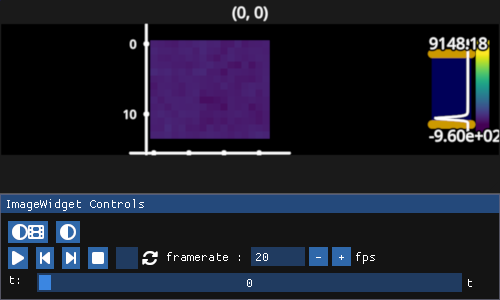

In [7]:
iw = fpl.ImageWidget(movie, cmap="viridis")
iw.show()

In [8]:
from skophys.preprocessing import Vectorizer, UnVectorizer

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [9]:
X = Vectorizer().transform(movie)
unvec = UnVectorizer(movie.shape[1:])

In [10]:
import scipy

In [11]:
lag = 2
lag_step = 1
n_pixels = X.shape[0]

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

In [12]:
H.shape

(952, 1997)

In [13]:
mu0 = H[:lag * n_pixels].mean(axis=1)
mu1 = H[lag * n_pixels:].mean(axis=1)

In [14]:
H[:lag * n_pixels] -= mu0[:, None]
H[lag * n_pixels:] -= mu1[:, None]

In [15]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

# k: number of components

In [16]:
k = 4

# list of slices of lags, each slice is the indices in `W` that represent pixels for one lag time

In [17]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag * 2)]
lag_slices

[slice(0, 238, None),
 slice(238, 476, None),
 slice(476, 714, None),
 slice(714, 952, None)]

In [18]:
H = np.vstack(
    [
        scipy.linalg.pinv(scipy.linalg.sqrtm(past @ past.T / past.shape[1])) @ past,
        scipy.linalg.pinv(scipy.linalg.sqrtm(future @ future.T / future.shape[1])) @ future,
    ]
)

In [19]:
H.shape

(952, 1997)

In [20]:
X_init = H

In [21]:
cov = X_init.T @ X_init

XTX = cov / np.linalg.norm(cov, ord="fro")

T = XTX.shape[0]

In [22]:
convergence = False
etamax = 0.05
eta = etamax

scounter = 1

In [23]:
from tqdm.notebook import tqdm

In [ ]:
Ys = list()

Y = (np.random.randn(k, T) / np.sqrt(T))

# Y /= Y.max()
# Y *= X.max()

for iteration in tqdm(range(40_000)):
    Ys.append(Y)
    Y_old = Y
    Y = Y + eta * Y @ (XTX - Y.T @ Y)
    # Y = Y.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta

    if er < 1e-3:
        convergence = True
        break

  0%|          | 0/40000 [00:00<?, ?it/s]

In [125]:
er

2.7093467742480826

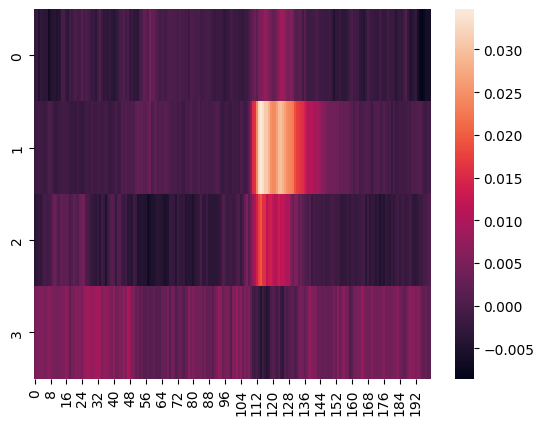

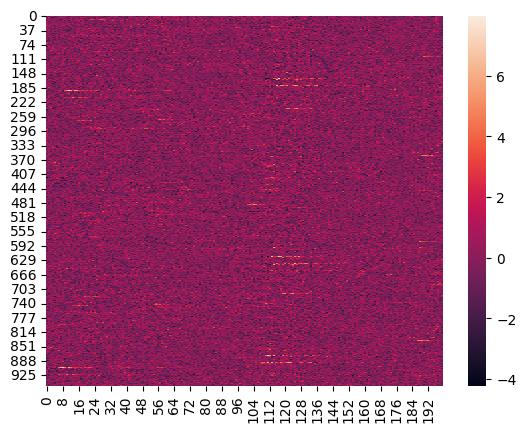

In [126]:
sns.heatmap(Y[:, :200])
plt.show()

sns.heatmap(X_init[:, :200])
plt.show()

In [127]:
W = Y @ X_init.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [128]:
W.shape

(4, 952)

In [129]:
Y.shape

(4, 1997)

<Axes: >

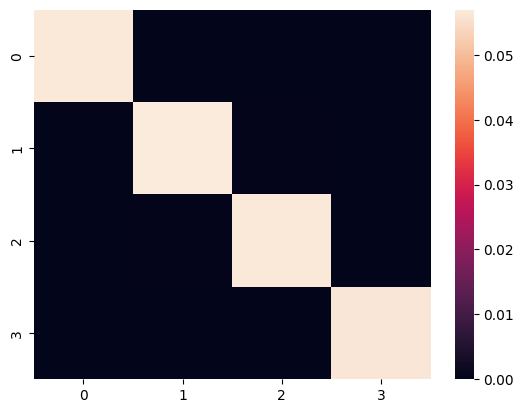

In [130]:
sns.heatmap(M)

In [131]:
np.linalg.eigvals(M)

array([0.05708214, 0.05661283, 0.05624404, 0.05631028])

In [132]:
F = np.linalg.inv(M) @ W

In [133]:
F /= F.sum(axis=1)[:, None]

In [134]:
F.shape

(4, 952)

In [135]:
from itertools import product

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='600.0px', css_width='1200.0px')
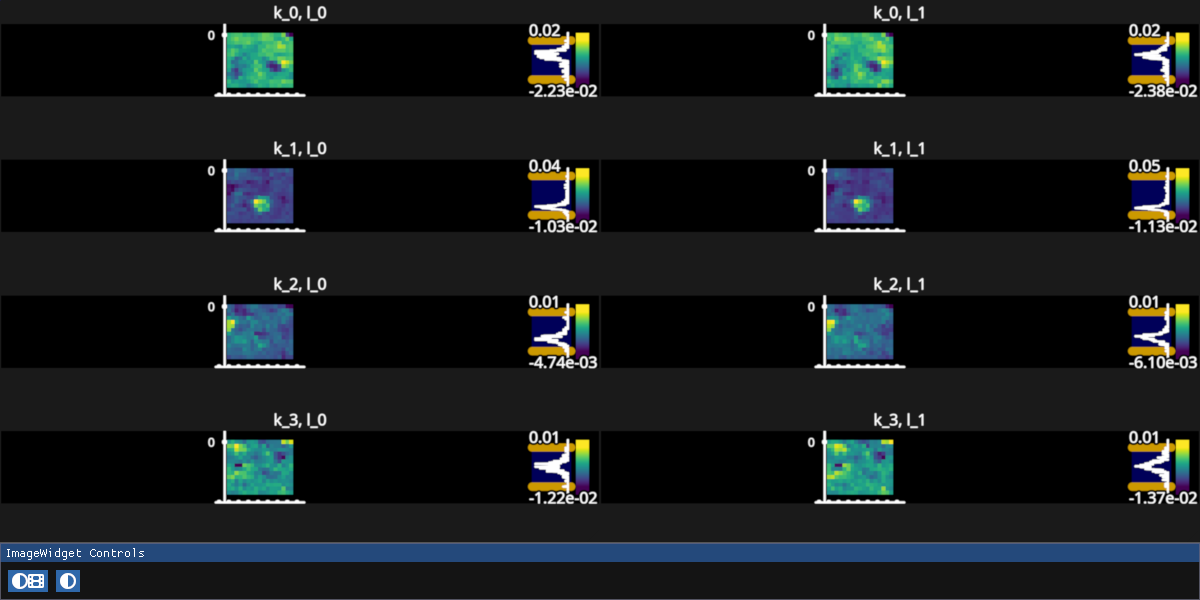

In [136]:
# make images by reshaing each lag within `W`
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(F[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (1200, 600)},
)
iw_W.show()

In [59]:
from ipywidgets import HBox

In [60]:
Y /= Y.max()
Y *= 10

In [65]:
iw_movie = fpl.ImageWidget(unvec.transform(X_init), cmap="viridis")
iw_movie.show()

fig = fpl.Figure()
lg = fig[0, 0].add_line(Y[11])
selector = lg.add_linear_selector()

@selector.add_event_handler("selection")
def index_changed(ev):
    ix = ev.get_selected_index()
    iw_movie.current_index = {"t": ix}

HBox([iw_movie.show(), fig.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [66]:
lg.data[:, 1] = Y[4]